# 7 测试

## 环境依赖

In [1]:
import unicodedata
import string
import re
import random
import time
import math

import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from nltk.translate.bleu_score import SmoothingFunction,sentence_bleu
from tqdm import tqdm
from torch.utils.data import Dataset
import numpy as np
from torch.autograd import Variable
import jieba

/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


如果使用GPU，则将下面的变量设为`True`。

In [2]:
USE_CUDA = True

## 读取数据

我们将读取目录下的`cn-eng.txt`文件，其中每一行是一个平行句对，例子如下：

```
我很冷。    I am cold.
```

### 对于单词进行编号

这里引入了两个特殊符号，“SOS”即“Start of sentence”和“EOS”即“End of sentence”。他们会加到输入文本的两端，以控制解码过程。

In [3]:
PAD_token = 0
SOS_token = 1
EOS_token = 2

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "PAD",1: "SOS", 2: "EOS"}
        self.n_words = 3 # Count SOS and EOS
      
    def index_words(self, sentence):
        # if self.name == 'cn':   
        #     for word in sentence:
        #         self.index_word(word)
        # else:
        #     for word in sentence.split(' '):
        #         self.index_word(word)
        
        # 中文jieba分词后，跟英文一样，句对都是按空格分离
        for word in sentence.split(' '):
            self.index_word(word)

    def index_word(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

### 文本预处理

丢弃除了中文、字母和常用标点之外的符号。

In [4]:
# Turn a Unicode string to plain ASCII, thanks to http://stackoverflow.com/a/518232/2809427
def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

# Lowercase, trim, and remove non-letter characters
def normalize_string(s):
    s = unicode_to_ascii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    # 保留英文引号和数字(全角数字０-９对应的unicode编码为\uff10-\uff19)
    # s = re.sub(r"[^a-zA-Z\u4e00-\u9fa5.!?，。？]+", r" ", s)
    s = re.sub(r"[^0-9\uff10-\uff19a-zA-Z\u4e00-\u9fa5'.!?，。？]+", r" ", s)
    return s

读取平行语料，并进行清理。

In [5]:
def read_langs(lang1, lang2, reverse=False):
    print("Reading lines...")

    # Read the file and split into lines
    lines = open('%s-%s.txt' % (lang1, lang2)).read().strip().split('\n')
    
    # 训练集和验证集按8:2分离     
    lines_train, lines_val = train_test_split(lines, test_size=0.2, random_state=10)

    # Split every line into pairs and normalize
    pairs_train = [[normalize_string(s) for s in l.split('\t')] for l in lines_train]
    pairs_val = [[normalize_string(s) for s in l.split('\t')] for l in lines_val]
    
    # Reverse pairs, make Lang instances
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)
        
    return input_lang, output_lang, pairs_train, pairs_val

### 过滤句子

样例为了加快训练，只保留了不长于10个单词的句对，真正实验中将更多数据考虑进来可能获得更好的效果。

In [6]:
MAX_LENGTH = 40

def filter_pair(p):
    return len(p[1].split(' ')) < MAX_LENGTH

def filter_pairs(pairs):
    return [pair for pair in pairs if filter_pair(pair)]

处理数据的全过程：

- 读取数据，每一行分别处理，将其转换成句对
- 对于文本进行处理，过滤无用符号
- 根据已有文本对于单词进行编号，构建符号到编号的映射


In [7]:
def prepare_data(lang1_name, lang2_name, reverse=False):
        
    input_lang, output_lang, pairs_train, pairs_val = read_langs(lang1_name, lang2_name, reverse)
    print("Read %s sentence pairs for train" % len(pairs_train))
    pairs_train = filter_pairs(pairs_train)
    print("Trimmed to %s sentence pairs for train" % len(pairs_train))
    print("Read %s sentence pairs for validate" % len(pairs_val))
    pairs_val = filter_pairs(pairs_val)
    print("Trimmed to %s sentence pairs for validate" % len(pairs_val))

    print("Indexing words...")
    for pair in pairs_train:
        # 对中文进行Jieba分词
        pair[0] =' '.join(jieba.cut(pair[0]))
        input_lang.index_words(pair[0])
        output_lang.index_words(pair[1])
    for pair in pairs_val:
        # 对中文进行Jieba分词
        pair[0] =' '.join(jieba.cut(pair[0]))
        input_lang.index_words(pair[0])
        output_lang.index_words(pair[1])

    return input_lang, output_lang, pairs_train, pairs_val

# 训练集:pairs_train; 验证集:pairs_val
input_lang, output_lang, pairs_train, pairs_val = prepare_data('cn', 'eng', False)

# 随机打印一条训练集和验证集的句对
print(random.choice(pairs_train))
print(random.choice(pairs_val))

Reading lines...


Building prefix dict from the default dictionary ...
Loading model from cache /tmp/jieba.cache


Read 72000 sentence pairs for train
Trimmed to 71907 sentence pairs for train
Read 18000 sentence pairs for validate
Trimmed to 17980 sentence pairs for validate
Indexing words...


Loading model cost 0.462 seconds.
Prefix dict has been built successfully.


['你 被 抢劫 过 吗 ？', 'have you ever been robbed ?']
['你 看過 這麼 美的 夕陽 嗎   ?', 'have you ever seen such a beautiful sunset ?']


## 将文本数据转换为张量

为了训练，我们需要将句子变成神经网络可以理解的东西（数字）。每个句子将被分解成单词，然后变成张量，其中每个单词都被索引替换（来自之前的Lang索引）。在创建这些张量时，我们还将附加EOS令牌以表示该句子已结束。

![](https://i.imgur.com/LzocpGH.png)

In [8]:
# Return a list of indexes, one for each word in the sentence
def indexes_from_sentence(lang, sentence):
    # if lang.name == 'cn':
    #     return [lang.word2index[word] for word in sentence]
    # else:
    #     return [lang.word2index[word] for word in sentence.split(' ')]

    # jieba中文分词
    # if lang.name == 'cn':
    #     # sentence = jieba.lcut(sentence)
    #     return [lang.word2index[word] for word in sentence]
    # else:
    return [lang.word2index[word] for word in sentence.split(' ')]

def variable_from_sentence(lang, sentence):
    indexes = indexes_from_sentence(lang, sentence)
    indexes.append(EOS_token)
    # var = torch.LongTensor(indexes).view(-1, 1)
    # if USE_CUDA: 
    #     var = var.cuda()
    # return var
    return indexes

def variables_from_pair(pair):
    input_variable = variable_from_sentence(input_lang, pair[0])
    target_variable = variable_from_sentence(output_lang, pair[1])
    return (input_variable, target_variable)


def indexes_from_sentence_test(lang, sentence):
    indexes_test = []
    for word in sentence.split(' '):
        if word in lang.word2index:
            indexes_test.append(lang.word2index[word])
        else:
            indexes_test.append(PAD_token)            
    return indexes_test

def variable_from_sentence_tet(lang, sentence):
    indexes = indexes_from_sentence_test(lang, sentence)
    indexes.append(EOS_token)
    return indexes

### 批处理

In [9]:
class Seq2eq_dataset(Dataset):
    def __init__(self, pairs):
        self.input_variable_list = []
        self.target_variable_list = []
        for pair in pairs:
            i,t =variables_from_pair(pair)
            self.input_variable_list.append(i)
            self.target_variable_list.append(t)

    def __len__(self):
        return len(self.input_variable_list)
        
    def __getitem__(self, i):
        input_variable = self.input_variable_list[i]
        target_variable = self.target_variable_list[i]
        return input_variable, target_variable, len(input_variable), len(target_variable)


In [10]:
def seq2eq_collate_func(batch):
    input_variable_list = []
    target_variable_list = []
    input_len_list = []
    target_len_list = []

    # 取批内最大长度
    for d in batch: 
        input_len_list.append(d[2])
        target_len_list.append(d[3])    
    max_len_src = max(input_len_list)
    max_len_trg = max(target_len_list)
    
    for d in batch:     
         
        # 源语句处理：按右填充
        padded_source = np.pad(np.array(d[0]), 
                                pad_width=((0,max_len_src-d[2])),          
                                mode="constant", constant_values=PAD_token)

        input_variable_list.append(padded_source)
        
        # 目标语句处理：按右填充
        padded_target = np.pad(np.array(d[1]), 
                                pad_width=((0,max_len_trg-d[3])),     
                                mode="constant", constant_values=PAD_token)
        target_variable_list.append(padded_target)
        
    #批内数据排序
    sort_idx = sorted(range(len(input_len_list)), key=input_len_list.__getitem__, reverse=True)
    input_variable_list = np.array(input_variable_list)[sort_idx]
    target_variable_list = np.array(target_variable_list)[sort_idx]
    input_len_list = np.array(input_len_list)[sort_idx]
    target_len_list = np.array(target_len_list)[sort_idx]


    # if USE_CUDA: 
    #     return [torch.tensor(input_variable_list).cuda(), 
    #             torch.tensor(target_variable_list).cuda(), 
    #             torch.LongTensor(input_len_list), 
    #             torch.LongTensor(target_len_list)] 

    return [torch.from_numpy(input_variable_list),torch.from_numpy(target_variable_list),torch.from_numpy(input_len_list),torch.from_numpy(target_len_list)]

In [11]:
batch_size = 4
num_workers = 16
train_loader = torch.utils.data.DataLoader(Seq2eq_dataset(pairs_train),
                                           collate_fn = seq2eq_collate_func,
                                           batch_size = batch_size, 
                                           shuffle=True, 
                                           num_workers=num_workers)
val_loader = torch.utils.data.DataLoader(Seq2eq_dataset(pairs_val),
                                           collate_fn = seq2eq_collate_func,
                                           batch_size = batch_size, 
                                           shuffle=True, 
                                           num_workers=num_workers)


In [12]:
pairs_train[:5]

[['她 也 学习 汉语 。', 'she learns chinese too .'],
 ['我累 得 只 想 躺 在 床上 。', 'i was too tired to care for anything but bed .'],
 ['我 在 信封 上 写错 了 地址 。', 'i wrote the wrong address on the envelope .'],
 ['我们 去 看 电影吧  ', "let's go to the movies ."],
 ['他 還沒有 真正 去 過美國 。', "he hasn't actually been to america ."]]

# 组件模型

## 编码器

In [13]:
class EncoderBiLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, n_layers=1):
        super(EncoderBiLSTM, self).__init__()
        
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        
        self.embedding = nn.Embedding(input_size, hidden_size)
        #双向循环
        self.bi_lstm = nn.LSTM(hidden_size, hidden_size, n_layers, bidirectional=True)
      
   
    def forward(self, word_inputs, input_lengths, hidden):

        # 在多个批次的多个序列上一次执行所有操作
        embedded = self.embedding(word_inputs)
        # 对填充过的数据进行压缩
        packed = torch.nn.utils.rnn.pack_padded_sequence(embedded, input_lengths)
        outputs, (hidden, cell) = self.bi_lstm(packed, hidden)
        # 解压，返回填充
        outputs, output_lengths = torch.nn.utils.rnn.pad_packed_sequence(outputs)
        # 构造输出数据（shape为[seq_len, batch_size,hidden_size]）,#双向循环
        outputs = outputs[:, :, :self.hidden_size] + outputs[:, :, self.hidden_size:] 
        # outputs = outputs[:, :, :]
        
        return outputs, hidden, output_lengths

    def init_hidden(self,batch_size):
        # 初始化隐藏状态和单元状态 #双向循环x2
        hidden = torch.zeros(self.n_layers *2, batch_size, self.hidden_size)
        cell = torch.zeros(self.n_layers *2, batch_size, self.hidden_size)
        if USE_CUDA: 
            hidden = hidden.cuda()
            cell = cell.cuda()
        return hidden, cell


## 解码器

In [14]:
class Attition(nn.Module):
    """
    部分代码参考自：
    https://github.com/spro/practical-pytorch/blob/master/seq2seq-translation/seq2seq-translation-batched.ipynb
    """  
    def __init__(self, hidden_size):
        super(Attition, self).__init__()
        
        self.hidden_size = hidden_size

        self.attn = nn.Linear(self.hidden_size * 2, hidden_size)
        self.v = nn.Parameter(torch.FloatTensor(hidden_size))

    def forward(self, hidden, encoder_outputs):
        max_len = encoder_outputs.size(0)
        batch_size = encoder_outputs.size(1)

        # att： B x S
        att = Variable(torch.zeros(batch_size, max_len))     
            
        # 因为没有使用batchfrist,须调整三维张量中的1、2维位置.(B, S, N)
        hidden_expand = hidden.expand(max_len, -1, -1).permute(1, 0, 2)  

        # (B, S, 2*N)->(B, S, N)
        enc_cat_hid = torch.cat([encoder_outputs.permute(1,0,2), hidden_expand], dim=-1) 

        # enc_cat_hid: (B, S, N); v: (N); att：(B, S)
        att = torch.matmul(self.attn(enc_cat_hid), self.v) 

        # 如果维度为1，插入一个维度（ 1 x B x S）
        if att.dim() == 1:
            att = att.unsqueeze(0)

        # 注意力分数计算
        alpha = F.softmax(att, dim=1)
        return alpha.unsqueeze(1)
    

class DecoderAttentionLSTM(nn.Module): 
    """
    部分代码参考自：
    https://github.com/spro/practical-pytorch/blob/master/seq2seq-translation/seq2seq-translation-batched.ipynb
    """    
    def __init__(self, hidden_size, output_size, n_layers=1, dropout_p=0.1):
        super(DecoderAttentionLSTM, self).__init__()

        # Keep for reference
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers

        # 定义层
        self.embedding = nn.Embedding(output_size, hidden_size, padding_idx=PAD_token)
        self.dropout = nn.Dropout(dropout_p)        
        self.lstm = nn.LSTM(hidden_size, hidden_size, n_layers,dropout=dropout_p)        
        self.concat = nn.Linear(hidden_size * 2, hidden_size)
        self.out = nn.Linear(hidden_size, output_size)        
   
        self.attn = Attition(hidden_size)

    def forward(self, word_input, last_hidden, encoder_outputs):
        # 获取当前输入词嵌入
        batch_size = word_input.size(0)
        word_embedded = self.embedding(word_input)
        word_embedded = self.dropout(word_embedded)
        word_embedded = word_embedded.view(1, batch_size, self.hidden_size) # S=1 x B x N
        # output = F.relu(word_embedded)
        
        lstm_output, (hidden,cell) = self.lstm(word_embedded, last_hidden)

        # 根据当前LSTM状态和编码器输出计算注意力权重；
        attn_weights = self.attn(lstm_output, encoder_outputs)

        lstm_output = lstm_output.squeeze(0) # S=1 x B x N -> B x N

        # 注意力权重和编码器输出加权。bmm用来对两个三维矩阵进行矩阵乘法
        context = attn_weights.bmm(encoder_outputs.transpose(0, 1)) # B x S=1 x N
        context = context.squeeze(1)       # B x S=1 x N -> B x N

        # 转换维度到hidden_size，方便后续LSTM输入
        concat_input = torch.cat((lstm_output, context), 1)        
        concat_output = torch.tanh(self.concat(concat_input))

        output = self.out(concat_output)

        # 返回最终输出、隐藏状态和注意力权重（用于可视化）
        return output, hidden, attn_weights

# 训练

## 一次训练迭代

为了训练，我们首先通过编码器逐字运行输入语句，并跟踪每个输出和最新的隐藏状态。接下来，为解码器提供解码器的最后一个隐藏状态作为其第一隐藏状态，并向其提供`<SOS>`作为其第一输入。从那里开始，我们迭代地预测来自解码器的下一个单词。
    
### Teacher Forcing 和 Scheduled Sampling

"Teacher Forcing"指的是每次都基于完全准确的上文进行解码，这样训练模型收敛很快，但是会造成实际场景和训练场景有较大差别，因为实际场景上文也都是模型预测的，可能不准确，具体细节可参考[论文](http://minds.jacobs-university.de/sites/default/files/uploads/papers/ESNTutorialRev.pdf)。

观察Teacher Forcing的网络的输出，我们可以看到该网络语法连贯，但是偏离正确的翻译。可以将其为学会了如何听老师的指示，而未学习如何独自冒险。

解决强迫教师问题的方法称为“计划抽样”（[Scheduled Sampling](https://arxiv.org/abs/1506.03099)），它在训练时仅在使用目标值和预测值之间进行切换。我们将在训练时随机选择,有时我们将使用真实目标作为输入（忽略解码器的输出），有时我们将使用解码器的输出。

In [15]:
def sequence_mask(sequence_length, max_len=None):
    """
    Code paraphrased from 
    https://github.com/spro/practical-pytorch/blob/master/seq2seq-translation/masked_cross_entropy.py
    """
    if max_len is None:
        max_len = sequence_length.data.max()
    batch_size = sequence_length.size(0)
    seq_range = torch.arange(0, max_len).long()
    seq_range_expand = seq_range.unsqueeze(0).expand(batch_size, max_len).contiguous()
    if USE_CUDA:
        seq_range_expand = seq_range_expand.cuda()
    seq_length_expand = (sequence_length.unsqueeze(1)
                         .expand_as(seq_range_expand))
    return seq_range_expand < seq_length_expand



def masked_cross_entropy(logits, target, length):
    length = torch.LongTensor(length)

    if USE_CUDA:
        length = length.cuda()
    """
    Code paraphrased from 
    https://github.com/spro/practical-pytorch/blob/master/seq2seq-translation/masked_cross_entropy.py
    """
    
    
    """
    Args:
        logits: A Variable containing a FloatTensor of size
            (batch, max_len, num_classes) which contains the
            unnormalized probability for each class.
        target: A Variable containing a LongTensor of size
            (batch, max_len) which contains the index of the true
            class for each corresponding step.
        length: A Variable containing a LongTensor of size (batch,)
            which contains the length of each data in a batch.

    Returns:
        loss: An average loss value masked by the length.
    """

    # logits_flat: (batch * max_len, num_classes)
    logits_flat = logits.view(-1, logits.size(-1))
    # log_probs_flat: (batch * max_len, num_classes)
    log_probs_flat = F.log_softmax(logits_flat, dim=1)
    # target_flat: (batch * max_len, 1)
    target_flat = target.view(-1, 1)
    # losses_flat: (batch * max_len, 1)
    losses_flat = -torch.gather(log_probs_flat, dim=1, index=target_flat)
    # losses: (batch, max_len)
    losses = losses_flat.view(*target.size())
    # mask: (batch, max_len)
    mask = sequence_mask(sequence_length=length, max_len=target.size(1))
    losses = losses * mask.float()
    loss = losses.sum() / length.float().sum()
    return loss

In [16]:
def train(input_tensor, target_tensor, input_lengths, target_lengths, encoder, decoder, 
          encoder_optimizer, decoder_optimizer, teacher_forcing_ratio, clip=10.0):
    decoder.train()
    encoder.train()
    
    
    batch_size = input_tensor.size(1)
    if USE_CUDA:
        input_tensor = input_tensor.cuda()
        target_tensor = target_tensor.cuda()
        
    # Run words through encoder
    encoder_hidden = encoder.init_hidden(batch_size)
    encoder_outputs, encoder_hidden, encoder_output_lengths = encoder(input_tensor, input_lengths,encoder_hidden)


    # Prepare input and output variables
    decoder_input = torch.tensor([SOS_token]*batch_size)  # decoder_input: torch.Size([1, 32])
    decoder_hidden = encoder_hidden[:decoder.n_layers] 
    # Use last (forward) hidden state from encoder
    all_decoder_outputs = Variable(torch.zeros(target_lengths.max(), batch_size, decoder.output_size))
    if USE_CUDA:
        decoder_input = decoder_input.cuda()
        all_decoder_outputs = all_decoder_outputs.cuda()
    
    # Added onto for each word
    loss = 0 

    # Choose whether to use teacher forcing
    use_teacher_forcing = random.random() < teacher_forcing_ratio
    
    if use_teacher_forcing:
        # Teacher forcing: Feed the target as the next input
        for di in range(target_lengths.max()):
            # decoder_output, decoder_hidden = decoder(decoder_input, [decoder_hidden, decoder_hidden], batch_size)
                            #print(decoder_hidden[0].size())
            # attention
            decoder_output, decoder_hidden, decoder_attention = decoder(decoder_input, [decoder_hidden,decoder_hidden], encoder_outputs)
                
            decoder_input = target_tensor[di]  # Teacher forcing
            all_decoder_outputs[di] = decoder_output
            
    else:
        # Without teacher forcing: use its own predictions as the next input
        for di in range(target_lengths.max()):
            # decoder_output, decoder_hidden = decoder(decoder_input, [decoder_hidden, decoder_hidden], batch_size)
            
            # attention
            decoder_output, decoder_hidden, decoder_attention = decoder(decoder_input, [decoder_hidden,decoder_hidden], encoder_outputs)
            
            topv, topi = decoder_output.topk(1)

            decoder_input = topi.squeeze().detach()  # detach from history as input
            all_decoder_outputs[di] = decoder_output
           

    # zero out the accumulated gradient over mini-batch
    encoder_optimizer.zero_grad()  
    decoder_optimizer.zero_grad()

    # Loss calculation and backpropagation

    loss = masked_cross_entropy(
        all_decoder_outputs.transpose(0, 1).contiguous(), # -> batch x seq
        target_tensor.transpose(0, 1).contiguous(), # -> batch x seq
        target_lengths
    )
    
    # loss = loss.sum()/batch_size 
    loss.backward()
    # ave_loss.backward()
    
    # Clip gradient norms
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), clip)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), clip)
    
    encoder_optimizer.step()   # update parameters
    decoder_optimizer.step()

    return loss.item()
     

### 验证方法

In [17]:
def get_batch_outputs(encoder, decoder, input_sentences, input_lengths, output_lengths): 
    with torch.no_grad():
        input_tensor = input_sentences.transpose(0,1)
        if USE_CUDA:
            input_tensor = input_tensor.cuda()
        batch_size = input_tensor.size(1)
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden,encoder_output_lengths = encoder(input_tensor, input_lengths, encoder_hidden)
          
        decoder_hidden = encoder_hidden[:decoder.n_layers]

        decoder_input = Variable(torch.tensor([SOS_token]*batch_size))
        if USE_CUDA:
            decoder_input = decoder_input.cuda()
        decoded_words = np.empty((output_lengths.max(), batch_size), dtype=object)

        for di in range(output_lengths.max()):
            # decoder_output, decoder_hidden = decoder(decoder_input, [decoder_hidden, decoder_hidden], batch_size)
            # attention
            decoder_output, decoder_hidden, decoder_attention = decoder(decoder_input, [decoder_hidden,decoder_hidden], encoder_outputs)

            topv, topi = decoder_output.topk(1)
            decoder_input = topi.flatten().detach() 
            if USE_CUDA:
                decoder_input = decoder_input.cuda()

            decoded_words[di:] = np.array(['' if idx==EOS_token else output_lang.index2word[idx] for idx in decoder_input.tolist()])

        # print(decoded_words.transpose())
        return decoded_words.transpose()

def evaluate(encoder, decoder, loader):
  
    """
    Thanks for the sacrebleu.py in 
    github https://github.com/mjpost/sacreBLEU/blob/master/sacrebleu.py#L1022-L1080
    """
    
    encoder.eval()
    decoder.eval()
    
    score = []
    src_sentences = []
    sys_sentences = []
    ref_sentences = []
    encoder.train(False)
    decoder.train(False)
    for i, (input_sentences, target_sentences, input_len, target_len) in enumerate(loader):
        # print(target_sentences)
        for sentence in target_sentences:
            # print(sentence)
            trg_list = []
            for idx in sentence:
                if idx.item() == EOS_token:
                    break
                else:
                    trg_list.append(output_lang.index2word[idx.item()])
            ref_sentences.append(' '.join(trg_list))
        for sentence in input_sentences:
            src_list = []
            for idx in sentence:
                if idx.item() == EOS_token:
                    break
                else:
                    src_list.append(input_lang.index2word[idx.item()])
            src_sentences.append(' '.join(src_list))

        # ref_sentences.append(' '.join(sent) for sent in target_sentences)
        #src_sentences.append(' '.join(sent) for sent in input_sentences)
        batch_size = input_sentences.size(0)
        batch_outputs = get_batch_outputs(encoder, decoder, input_sentences, input_len, target_len)
        for sentence in batch_outputs:
            try:
                end_idx = sentence.tolist().index('')
                sys_sentences.append(' '.join(sentence[:end_idx]))
            except ValueError:
                sys_sentences.append(' '.join(sentence))
            
    encoder.train(True)
    decoder.train(True) 

    return src_sentences, sys_sentences, ref_sentences

### 辅助输出训练情况的函数

In [18]:
def as_minutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)

def time_since(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent)
    rs = es - s
    return '%s (- %s)' % (as_minutes(s), as_minutes(rs))

In [19]:
def trainIters(encoder, decoder, epochs, encoder_optimizer, decoder_optimizer, teacher_forcing_ratio,
               print_every=10, plot_every=1000, evaluate_every=3000):
    start = time.time()


    score_max = 0
    plot_losses = []
    validation_score = []
    
    for epoch in range(1, epochs + 1):
        with tqdm(total=len(train_loader), desc=f"[Epoch {epoch:3d}/{epochs}]") as pbar:
            print_loss_total = 0  # Reset every print_every
            plot_loss_total = 0  # Reset every plot_every
            
            for i, (input_variable, target_variable,input_len,target_len) in enumerate(train_loader): 
                encoder.train()
                decoder.train()
                
                input_tensor = input_variable.transpose(0,1)   
                target_tensor = target_variable.transpose(0,1)
                loss = train(input_tensor, target_tensor, input_len, target_len, 
                             encoder, decoder, encoder_optimizer, decoder_optimizer, teacher_forcing_ratio)
                print_loss_total += loss
                plot_loss_total += loss
    
                        
                if i > 0 and i % print_every == 0:
                    print_loss_avg = print_loss_total / print_every
                    print_loss_total = 0

                    pbar.set_postfix({'Train Loss': '[{:4f}(avg. {:4f})]'.format(loss,print_loss_avg)})
                    pbar.update(print_every)
                    
                if i > 0 and i % plot_every == 0:
                    plot_loss_avg = plot_loss_total / plot_every
                    plot_losses.append(plot_loss_avg)
                    plot_loss_total = 0
                torch.cuda.empty_cache()    
            # print("plot_losses:",plot_losses)
            # print("validation_scores:",validation_scores)
        
        # 计算epoch的BLEU
        src_sentences, sys_sentences, ref_sentences = evaluate(encoder, decoder, val_loader)
        bleu_scores = list() 
        for i in range(len(src_sentences)):
            bleu_score = sentence_bleu([ref_sentences[i].split()], sys_sentences[i].split(), smoothing_function= SmoothingFunction().method4)
            bleu_scores.append(bleu_score)
        bleu_scores_epoch = np.average(bleu_scores)

        # 如果是历史新高，保存模型
        if len(validation_score)==0 or bleu_scores_epoch > np.max(validation_score):
            state = {'epoch': epoch,
                'bleu': bleu_scores_epoch,
                'encoder': encoder,
                'decoder': decoder,
                'encoder_optimizer': encoder_optimizer,
                'decoder_optimizer': decoder_optimizer}
            torch.save(state, './output/bi-lstm_attention_{0}.pth.tar'.format(epoch))
        validation_score.append(np.average(bleu_scores))

    return plot_losses, validation_score

## 进行训练

以下设置变量用于绘制图标和跟踪进度：

In [20]:
# Configuring training
n_epochs = 24
# plot_every = 1
print_every = 10
plot_losses = []

# Keep track of time elapsed and running averages
# start = time.time()
# plot_losses = []
# print_loss_total = 0 # Reset every print_every
# plot_loss_total = 0 # Reset every plot_every

hidden_size = 512
n_layers = 4
dropout_p = 0.1
teacher_forcing_ratio = 0.5
clip = 10

# Initialize models
encoder = EncoderBiLSTM(input_lang.n_words, hidden_size, n_layers)
decoder = DecoderAttentionLSTM(hidden_size, output_lang.n_words, n_layers, dropout_p=dropout_p)

# Move models to GPU
if USE_CUDA:
    encoder.cuda()
    decoder.cuda()

# Initialize optimizers and criterion
learning_rate = 0.0001
encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)
criterion = nn.NLLLoss()


要进行实际训练，我们会多次调用训练函数，并在进行过程中打印中间信息。

In [21]:
plot_losses, validation_scores = trainIters(encoder, decoder, n_epochs, encoder_optimizer, decoder_optimizer, teacher_forcing_ratio, print_every=print_every)

[Epoch  24/24]: 100%|█████████▉| 17970/17977 [18:18<00:00, 16.36it/s, Train Loss=[0.969245(avg. 0.349795)]]


## loss 和bleu可视化

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


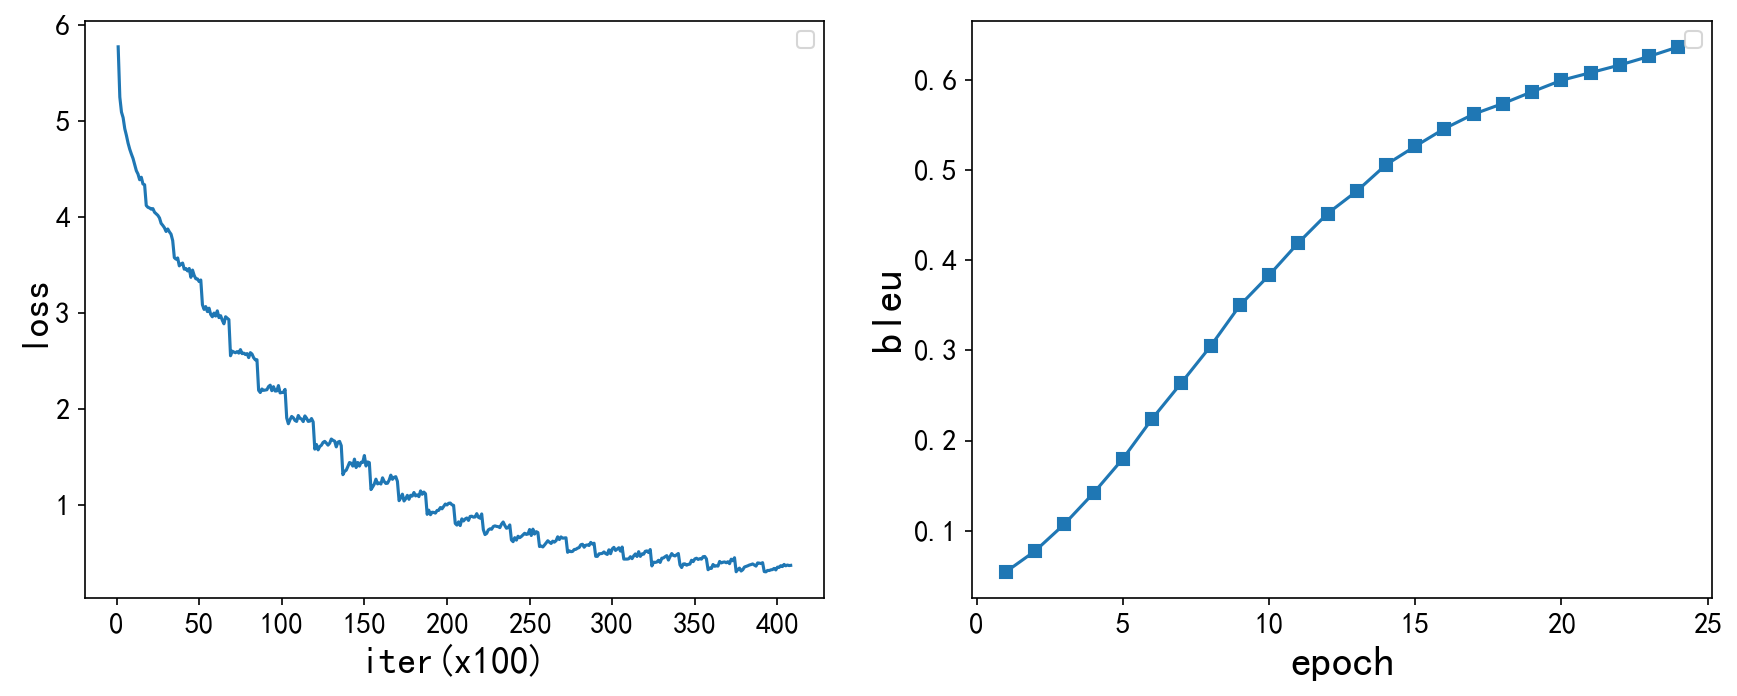

In [22]:
import matplotlib.pyplot as plt

# plt.figure()
# fig, ax = plt.subplots()
# loc = ticker.MultipleLocator(base=0.2) # put ticks at regular intervals
# ax.yaxis.set_major_locator(loc)
# plt.plot(plot_losses)



plt.figure(figsize=(14,5), dpi=150)
plt.rcParams['font.sans-serif']=['SimHei']
plt.subplot(121)
plt.plot(range(1,len(plot_losses)+1), plot_losses)
plt.xlabel('iter(x100)', fontsize=18, fontweight='bold')
plt.ylabel('loss', fontsize=18, fontweight='bold')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.subplot(122)
plt.plot(range(1,len(validation_scores)+1), validation_scores, marker='s')
plt.xlabel('epoch', fontsize=20, fontweight='bold')
plt.ylabel('bleu', fontsize=20, fontweight='bold')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

In [23]:
plot_losses

[5.775861860275269,
 5.251740042924881,
 5.095696728229523,
 5.036865785837174,
 4.921710753202438,
 4.851636191606522,
 4.771442324638366,
 4.708465793848037,
 4.657882562160492,
 4.611546796798706,
 4.549606521606445,
 4.484225667715073,
 4.44944686460495,
 4.390038903713227,
 4.4162199175357815,
 4.345916804075241,
 4.337999771118164,
 4.121760006427765,
 4.102981323719025,
 4.095774331331253,
 4.083209286212921,
 4.089494804859162,
 4.051391583800316,
 4.035589984416962,
 4.019015529155731,
 3.9920846831798555,
 3.935237223148346,
 3.914212380886078,
 3.889584823489189,
 3.850691085934639,
 3.876993627786636,
 3.8467922958135605,
 3.822339033126831,
 3.7557398060560225,
 3.577609630346298,
 3.5623459867239,
 3.5747967479228975,
 3.4922054290771483,
 3.5116483426094054,
 3.521434229493141,
 3.457605560183525,
 3.4647702885866165,
 3.4393737055063247,
 3.4648296750783922,
 3.3725723384618758,
 3.4482570608854295,
 3.3926728221178055,
 3.3578022298812864,
 3.355912036538124,
 3.328496

In [24]:
np.max(validation_scores)

0.6366449704653151

# 模型验证

In [25]:
model = torch.load('./output/bi-lstm_attention_16.pth.tar')
encoder_val = model['encoder']
decoder_val = model['decoder']
src_sentences, sys_sentences, ref_sentences = evaluate(encoder_val, decoder_val, val_loader)

### 取约定的数据进行验证

In [26]:

val_man = ['美國在一八六三年廢除了奴隸制度。',
            '关门。',
            '我不喝水。',
            '请安装linux!',
            '为什么我还在这里？',
            '這本書有一個弱點作者自己結了婚，但卻建議別人不要結婚，沒有甚麼說服力。']

pairs_man= []
for i in range(len(src_sentences)):
    # print('>', src_sentences[i])
    input_cn = src_sentences[i].replace(' ','')
    if input_cn in val_man and input_cn not in pairs_man:          
        pairs_man.append(input_cn) 
        
        print('>', input_cn)
        print('=', ref_sentences[i])
        print('<', sys_sentences[i])
        print('')

> 关门。
= close the door .
< shut the door .

> 我不喝水。
= i don't drink water .
< i don't drink water .

> 请安装linux!
= install linux !
< hey linux !

> 美國在一八六三年廢除了奴隸制度。
= america did away with slavery in 1863 .
< america did away with the won't in .

> 为什么我还在这里？
= why am i still here ?
< why should i have here ?

> 這本書有一個弱點作者自己結了婚，但卻建議別人不要結婚，沒有甚麼說服力。
= the weak point of this book is that it's less than persuasive when the married author recommends not being married .
< this great point of this book is that that that that is that no of being being being being being .



# 测试

In [27]:
beam_size = 10
n_best = 5
sentence_ratio = True

In [28]:
class beam_search(object):
    """
    代码参考：
    https://github.com/OpenNMT/OpenNMT-py/blob/master/onmt/translate/beam.py
    """
    def __init__(self, encoder, decoder, max_length, beam_size, attention = True,sentence_ratio = False): 
        super(beam_search, self).__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.attention = attention
        self.max_length = max_length
        self.beam_size = beam_size
        self.sentence_ratio = sentence_ratio
        
    def search(self, encoder_outputs, decoder_input, decoder_hidden, src_len):

        prob = {k:0 for k in range(self.beam_size)}
        bestSent = []
        bestScore = []       
        decoder_word_choices = {k:[] for k in range(self.beam_size)}
        decoder_hidden_choices = {}
        decoder_input_choices = {}
        decoder_output_choices = {}
        
        # Initialize beam serach
        if self.attention == True:
            decoder_output, decoder_hidden, decoder_attention = self.decoder(decoder_input.contiguous(), [decoder_hidden.contiguous(),decoder_hidden.contiguous()], encoder_outputs)
            decoder_output = F.log_softmax(decoder_output, dim=1)
            topv, topi = decoder_output.data.topk(self.beam_size)
        else: 
            print("Only available when attention = True")
        
        # Initialize beam candidates 
        for i in range(self.beam_size):
            decoder_word_choices[i].append(topi.squeeze()[i].item())
            decoder_input_choices[i] = topi.squeeze()[i].detach()
            decoder_hidden_choices[i] = decoder_hidden
            prob[i] += topv.squeeze()[i].detach()
            
        ## running beam search
        cur_len = 0
        max_length = 2*src_len if self.sentence_ratio else self.max_length
        # delete
#         print(self.sentence_ratio)
#         print(src_len)
#         print(max_length)
        
        while decoder_hidden_choices and cur_len <= max_length:
            cur_len += 1
            topi = {}
            key_list = list(decoder_hidden_choices.keys())
            scores = []
            for key in key_list:
                    
                decoder_output, decoder_hidden_choices[key],decoder_attn  = self.decoder(decoder_input_choices[key].unsqueeze(0), [decoder_hidden_choices[key],decoder_hidden_choices[key]],encoder_outputs)
                decoder_output_choices[key] = F.log_softmax(decoder_output, dim=1)
                topv, topi[key] = decoder_output_choices[key].data.topk(len(decoder_hidden_choices))
                scores.extend((topv+prob[key]).tolist()[0])
                
            scores = np.array(scores)   
            max_candidate_score = scores.argsort()[-len(decoder_hidden_choices):][::-1]
            decoded_sent_score = scores[max_candidate_score]

            choice_sentence = {}
            choiceHidden = {}
            trashOfKeys = []
            
            for j in range(len(max_candidate_score)):
                prev_choice_idx = key_list[int(np.floor(max_candidate_score[j]/len(decoder_hidden_choices)))]
                if topi[prev_choice_idx].squeeze().dim() == 0:
                    next_idx = topi[prev_choice_idx].squeeze()
                else:
                    next_idx = topi[prev_choice_idx].squeeze()[max_candidate_score[j] % len(decoder_hidden_choices)]
                
                s_choice = decoder_word_choices[prev_choice_idx].copy()
                s_choice.append(next_idx.item())
                choice_sentence[j] = s_choice
                h_choice = decoder_hidden_choices[prev_choice_idx]
                choiceHidden[j] = h_choice
                decoder_input_choices[j] = next_idx.detach()   
                prob[j] = decoded_sent_score[j] 
   
            decoder_word_choices = choice_sentence
            decoder_hidden_choices = choiceHidden
            
            for key, s in decoder_word_choices.items():
                if EOS_token in s:
                    bestSent.append(s)
                    bestScore.append(prob[key]) 
                    trashOfKeys.append(key)
                    
            for k in trashOfKeys:
                decoder_hidden_choices.pop(k)
                decoder_word_choices.pop(k)

        if len(bestScore) == 0:
            max_prob = prob[0]
            max_prob_idx = 0
            for k in prob.keys():
                if prob[k] > max_prob: 
                    max_prob_idx = k
                    max_prob = prob[k]
            bestScore.append(max_prob)
            bestSent.append(decoder_word_choices[max_prob_idx])
                
        return bestSent, bestScore


def get_batch_outputs(encoder, decoder, input_sentences, input_lengths, output_lengths): 
    with torch.no_grad():
        input_tensor = input_sentences.transpose(0,1)   # 32*100 to 100*32
        if USE_CUDA: 
            input_tensor= input_tensor.cuda()
        batch_size = input_tensor.size(1)
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden,encoder_output_lengths = encoder(input_tensor, input_lengths, encoder_hidden)
       
        decoder_hidden = encoder_hidden[:decoder.n_layers]

        decoder_input = Variable(torch.tensor([SOS_token]*batch_size))  # decoder_input: torch.Size([1, 32])
        if USE_CUDA: 
            decoder_input= decoder_input.cuda()
        decoded_words = np.empty((output_lengths.max(), batch_size), dtype=object)

        for di in range(output_lengths.max()):
            decoder_output, decoder_hidden, decoder_attention = decoder(
                decoder_input, [decoder_hidden,decoder_hidden], encoder_outputs)

            topv, topi = decoder_output.topk(1)
            decoder_input = topi.squeeze().detach()
            if USE_CUDA: 
                decoder_input= decoder_input.cuda()

            decoded_words[di:] = np.array(['' if idx==EOS_token else output_lang.index2word[idx] for idx in decoder_input.tolist()])

        return decoded_words.transpose()

def tester(encoder, decoder, input_sentences, input_lengths): #####
    with torch.no_grad():
        input_tensor = input_sentences.transpose(0,1)   # 32*100 to 100*32
        if USE_CUDA: 
            input_tensor= input_tensor.cuda()
        batch_size = input_tensor.size(1)
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden, encoder_output_lengths = encoder(input_tensor, input_lengths, encoder_hidden)
        
        decoder_hidden = encoder_hidden[:decoder.n_layers]
        my_beam_search = beam_search(encoder, decoder,input_sentences.max().item(), beam_size, True, sentence_ratio)
        beam_search_result = []
        for i in range(batch_size):
            decoder_input = torch.tensor([[SOS_token]], requires_grad=False)
            # print(decoder_input)
            if USE_CUDA: 
                decoder_input= decoder_input.cuda() 
            sentences, probs = my_beam_search.search(encoder_outputs[:,i,:].unsqueeze(1), decoder_input, 
                                                     decoder_hidden[:,i,:].unsqueeze(1), input_lengths[i].item())
            
            beam_search_result.append(sentences[probs.index(max(probs))])

        padded_beam_search_result = []

        max_length = 0
        for sentence in beam_search_result:
            if len(sentence) > max_length:
                max_length = len(sentence)

        for sentence in beam_search_result:
            while len(sentence) < max_length + 2:
                sentence.append(PAD_token)
            padded_beam_search_result.append(sentence)

        batch_sentences = []
        
        for sentence in padded_beam_search_result:
            sentence = [output_lang.index2word[k] for k in sentence]
            try:
                end_idx = sentence.index('')
                batch_sentences.append(' '.join(sentence[:end_idx]))
            except ValueError:
                batch_sentences.append(' '.join(sentence))
        # print(batch_sentences)
    return batch_sentences

In [29]:
model = torch.load('./output/bi-lstm_attention_16.pth.tar')
encoder_test = model['encoder']
decoder_test = model['decoder']
if USE_CUDA:
    encoder_test.cuda()
    encoder_test.cuda()

In [30]:
class Test_dataset(Dataset):
    def __init__(self, sentences):
        self.input_variable_list = []
        for src_sentence in sentences:
            input_var = variable_from_sentence_tet(input_lang,src_sentence)
            self.input_variable_list.append(input_var)

    def __len__(self):
        return len(self.input_variable_list)
        
    def __getitem__(self, i):
        input_variable = self.input_variable_list[i]
        return input_variable, len(input_variable)


def test_collate_func(batch):
    input_variable_list = []
    input_len_list = []

    # 取批内最大长度
    for d in batch: 
        input_len_list.append(d[1]) 
    max_len_src = max(input_len_list)
    
    for d in batch:    
         
        # 源语句处理：按右填充
        padded_source = np.pad(np.array(d[0]), 
                                pad_width=((0,max_len_src-d[1])),          
                                mode="constant", constant_values=PAD_token)

        input_variable_list.append(padded_source)
        
    #批内数据排序
    sort_idx = sorted(range(len(input_len_list)), key=input_len_list.__getitem__, reverse=True)
    input_variable_list = np.array(input_variable_list)[sort_idx]
    input_len_list = np.array(input_len_list)[sort_idx]


    return [torch.from_numpy(input_variable_list),torch.from_numpy(input_len_list)]

In [31]:
test_sentences = []
with open('./test.txt', encoding='UTF-8') as fd:
    for test in fd:
        test = test.strip()
        # 对中文进行Jieba分词
        test =' '.join(jieba.cut(test))
        # input_lang.index_words(test) # tet
        
        test_sentences.append(test)

In [32]:
test_loader = torch.utils.data.DataLoader(Test_dataset(test_sentences),
                                           collate_fn = test_collate_func,
                                           batch_size = batch_size, 
                                           shuffle=False, 
                                           num_workers=num_workers)

In [33]:

encoder_test.eval()
decoder_test.eval()

src_sentences = []
sys_sentences = []
encoder_test.train(False)
decoder_test.train(False)
for i, (input_variable, input_len) in enumerate(test_loader): 
    for sentence in input_variable:
        src_list = []
        for idx in sentence:
            if idx.item() == EOS_token:
                break
            else:
                src_list.append(input_lang.index2word[idx.item()])
        src_sentences.append(' '.join(src_list))

    # translation_output = tester(encoder_test, decoder_test, input_variable, input_len)
    # print(translation_output)
    # sys_sentences.extend(translation_output)

    for sentence in  get_batch_outputs(encoder_test, decoder_test, input_variable, input_len,input_len*3):
        try:
            end_idx = sentence.tolist().index('')
            sys_sentences.append(' '.join(sentence[:end_idx]))
        except ValueError:
            sys_sentences.append(' '.join(sentence))
        
        
encoder_test.train(True)
decoder_test.train(True) 

DecoderAttentionLSTM(
  (embedding): Embedding(12619, 512, padding_idx=0)
  (dropout): Dropout(p=0.1, inplace=False)
  (lstm): LSTM(512, 512, num_layers=4, dropout=0.1)
  (concat): Linear(in_features=1024, out_features=512, bias=True)
  (out): Linear(in_features=512, out_features=12619, bias=True)
  (attn): Attition(
    (attn): Linear(in_features=1024, out_features=512, bias=True)
  )
)

In [34]:
import pandas as pd
df = pd.DataFrame(columns=['cn','en'])

for i in range(len(src_sentences)):
    df.loc[len(df)] =[src_sentences[i].replace(' ',''),sys_sentences[i]]
df.to_csv('./7.result.txt', sep='\t', header=False, index=False)

In [38]:
df.sample(10)

,cn,en
3582,秘书把信塞到一个信封里。,the secretary carried the letter into an envel...
9667,你想要我叫警察吗？,do you want me to call the police ?
2479,我只想高兴。,i just want to be happy .
3973,她明天去買東西，她很開心。,she is going to buy a nice meal so she is happy .
7225,你是我的一切。,you mean everything to me .
1591,湯姆不會傷害任何人。,tom wouldn't hurt anyone .
7106,我能抱你吗？,is it ok i can hug you ?
9132,学习PAD语也给了我结识新朋友的机会。,it's ten enough to send me a new umbrella for ...
586,我更願意自己做。,i'd rather do it by myself .
2112,萨米已经看过电视上的每一个医学节目,already have already down a because of the the...
